# Kreditly Phase 2 — LendingClub model training

This notebook trains a historical loan outcome model and exports the artifacts used by the Streamlit site. Run it from the project root with the project `.venv` active. It reads the local, Git-ignored `data/lending_club_loan_two.csv`; it never writes the raw file to Git.

**Important scope:** this dataset is from U.S. LendingClub loans. The estimate is a classroom demonstration, is not validated for Indian borrowers, cannot assess current loan eligibility, and must not be used for lending decisions. It predicts the recorded outcome “Charged Off” among loans with resolved outcomes.

## 1. Load and inspect the supplied data

A row represents one LendingClub loan record. We check dimensions, column types, missingness, duplicates, and target balance before modeling. The chart makes target imbalance visible; accuracy alone will not be enough.

Shape: 396,030 rows × 27 columns


,dtype
loan_amnt,float64
term,object
int_rate,float64
installment,float64
grade,object
sub_grade,object
emp_title,object
emp_length,object
home_ownership,object
annual_inc,float64


,missing rows
mort_acc,37795
emp_title,22927
emp_length,18301
title,1756
pub_rec_bankruptcies,535
revol_util,276


Duplicate full rows: 0
Target labels:


,rows
loan_status,
Fully Paid,318357
Charged Off,77673


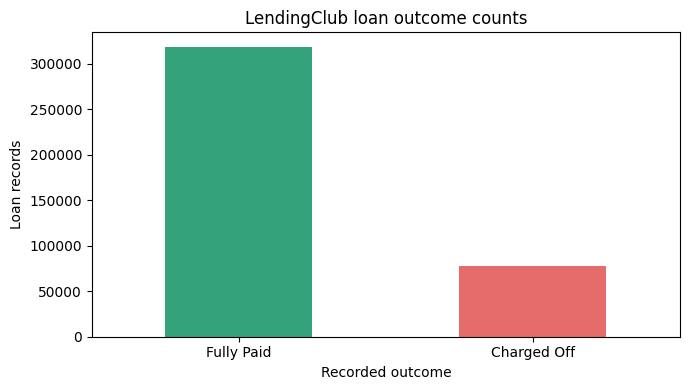

CSV SHA-256: 7e63af47a810b1f5d8304108d606a4788c671efc992d23c05751611a7d4c1fda
Issue month range: Jun-2007 to Dec-2016


In [1]:
from pathlib import Path
import hashlib
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

DATA_PATH = Path("data/lending_club_loan_two.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Place the supplied CSV at {DATA_PATH}; the raw dataset stays Git-ignored.")
raw = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
display(raw.dtypes.rename("dtype").to_frame())
missing = raw.isna().sum().sort_values(ascending=False)
display(missing[missing.gt(0)].rename("missing rows").to_frame())
print(f"Duplicate full rows: {raw.duplicated().sum():,}")
print("Target labels:")
display(raw["loan_status"].value_counts(dropna=False).rename("rows").to_frame())
target_counts = raw["loan_status"].value_counts()
ax = target_counts.reindex(["Fully Paid", "Charged Off"]).plot(
    kind="bar", color=["#34a27b", "#e66b6b"], figsize=(7, 4), rot=0
)
ax.set(title="LendingClub loan outcome counts", xlabel="Recorded outcome", ylabel="Loan records")
plt.tight_layout()
plt.show()
required = {
    "loan_amnt", "term", "int_rate", "installment", "grade", "sub_grade",
    "emp_title", "emp_length", "home_ownership", "annual_inc", "verification_status",
    "issue_d", "loan_status", "purpose", "title", "dti", "earliest_cr_line",
    "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc",
    "initial_list_status", "application_type", "mort_acc", "pub_rec_bankruptcies", "address",
}
missing_columns = sorted(required - set(raw.columns))
if missing_columns:
    raise ValueError(f"Expected columns are missing: {missing_columns}")
unknown_statuses = sorted(set(raw["loan_status"].dropna()) - {"Fully Paid", "Charged Off"})
if unknown_statuses:
    raise ValueError(f"Review unexpected target labels: {unknown_statuses}")
sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print("CSV SHA-256:", sha256)
issue_dates = pd.to_datetime(raw["issue_d"], format="%b-%Y", errors="coerce")
print("Issue month range:", issue_dates.min().strftime("%b-%Y"), "to", issue_dates.max().strftime("%b-%Y"))


## 2. Define the target and remove leakage or out-of-scope fields

The target is `loan_status`: **Charged Off = 1** (risky) and **Fully Paid = 0**.

| Column | Why it is excluded |
|---|---|
| `int_rate`, `grade`, `sub_grade`, `installment` | Lender pricing and grade are assigned after risk review; installment is determined by the priced loan terms. These can leak underwriting decisions. |
| `emp_title`, `title`, `address` | Free text/location can identify people, create high-cardinality noise, and proxy social or protected traits. |
| `initial_list_status` | Platform/servicing detail outside the requested borrower feature set. |
| `verification_status` | Platform-specific verification status, excluded to keep the inputs to the requested profile features. |
| `application_type` | Platform-specific product/process field outside the requested feature set. |

`issue_d` and `earliest_cr_line` are used only to calculate credit-history duration; they are not model inputs. Raw money columns are used only to calculate ratios and are then dropped from the feature matrix.

In [2]:
from src.features import FEATURES, NUMERIC_FEATURES, CATEGORICAL_FEATURES, features_from_dataset

LEAKAGE_AND_EXCLUDED = [
    "int_rate", "grade", "sub_grade", "installment", "emp_title", "title",
    "address", "initial_list_status", "verification_status", "application_type",
]
clean = raw.drop(columns=LEAKAGE_AND_EXCLUDED).copy()
target_map = {"Fully Paid": 0, "Charged Off": 1}
y = clean["loan_status"].map(target_map).astype("int8")
print("Target mapping:", target_map)
print("Excluded input columns:", LEAKAGE_AND_EXCLUDED)
print("Remaining columns used temporarily for feature construction:", clean.columns.tolist())
display(y.value_counts().rename(index={0: "Fully Paid (0)", 1: "Charged Off (1)"}).to_frame("rows"))

Target mapping: {'Fully Paid': 0, 'Charged Off': 1}
Excluded input columns: ['int_rate', 'grade', 'sub_grade', 'installment', 'emp_title', 'title', 'address', 'initial_list_status', 'verification_status', 'application_type']
Remaining columns used temporarily for feature construction: ['loan_amnt', 'term', 'emp_length', 'home_ownership', 'annual_inc', 'issue_d', 'loan_status', 'purpose', 'dti', 'earliest_cr_line', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'mort_acc', 'pub_rec_bankruptcies']


,rows
loan_status,
Fully Paid (0),318357
Charged Off (1),77673


## 3. Build the requested currency-free features

Shared `src/features.py` is used by this notebook and the website. It creates precisely 14 columns: 12 numeric inputs and categorical `purpose` and `home_ownership`.

Employment labels such as `< 1 year` and `10+ years` become numeric years; terms become 36 or 60 months. Credit history is `issue_d year − earliest_cr_line year`. Dataset categories and website choices are normalized; Rent/Own/Own with a home loan map to RENT/OWN/MORTGAGE.

Missing numeric values use the training median, including `mort_acc`. Missing categories become `Unknown`. Categories below 1% of training rows are grouped as `OTHER`. Numeric values are clipped to the training split's 1st–99th percentiles. These learned preprocessing values are fit inside the pipeline on training data only.

In [3]:
X = features_from_dataset(clean)
assert X.columns.tolist() == FEATURES
print("Feature matrix:", X.shape)
display(X.dtypes.rename("dtype").to_frame())
display(X.isna().sum().rename("missing before training-only imputation").to_frame())
display(X.describe(include="all").T)
print("Non-positive annual income rows:", int((raw["annual_inc"] <= 0).sum()))
print("Negative DTI rows:", int((raw["dti"] < 0).sum()))
print("Negative derived credit-history rows:", int((X["credit_history_years"] < 0).sum()))
print("Feature names:", FEATURES)

Feature matrix: (396030, 14)


,dtype
loan_to_income,float64
revol_bal_to_income,float64
dti,float64
revol_util,float64
open_acc,float64
total_acc,float64
pub_rec,float64
mort_acc,float64
pub_rec_bankruptcies,float64
term,float64


,missing before training-only imputation
loan_to_income,1
revol_bal_to_income,1
dti,0
revol_util,276
open_acc,0
total_acc,0
pub_rec,0
mort_acc,37795
pub_rec_bankruptcies,535
term,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
loan_to_income,396029.0,NaN,NaN,NaN,0.213413,0.128325,0.000309,0.125714,0.2,0.289655,40.0
revol_bal_to_income,396029.0,NaN,NaN,NaN,0.226371,0.208854,0.0,0.100972,0.183681,0.299443,41.221667
dti,396030.0,NaN,NaN,NaN,17.379514,18.019092,0.0,11.28,16.91,22.98,9999.0
revol_util,395754.0,NaN,NaN,NaN,53.791749,24.452193,0.0,35.8,54.8,72.9,892.3
open_acc,396030.0,NaN,NaN,NaN,11.311153,5.137649,0.0,8.0,10.0,14.0,90.0
total_acc,396030.0,NaN,NaN,NaN,25.414744,11.886991,2.0,17.0,24.0,32.0,151.0
pub_rec,396030.0,NaN,NaN,NaN,0.178191,0.530671,0.0,0.0,0.0,0.0,86.0
mort_acc,358235.0,NaN,NaN,NaN,1.813991,2.14793,0.0,0.0,1.0,3.0,34.0
pub_rec_bankruptcies,395495.0,NaN,NaN,NaN,0.121648,0.356174,0.0,0.0,0.0,0.0,8.0
term,396030.0,NaN,NaN,NaN,41.698053,10.212038,36.0,36.0,36.0,36.0,60.0


Non-positive annual income rows: 1
Negative DTI rows: 0
Negative derived credit-history rows: 0
Feature names: ['loan_to_income', 'revol_bal_to_income', 'dti', 'revol_util', 'open_acc', 'total_acc', 'pub_rec', 'mort_acc', 'pub_rec_bankruptcies', 'term', 'purpose', 'emp_length', 'home_ownership', 'credit_history_years']


## 4. Create a stratified 70/15/15 split

Stratification keeps the Charged Off share similar in train, validation, and test. Random seed 42 makes the split reproducible. Validation selects the model and tunes its threshold; test is reserved for final reporting.

In [4]:
from src.training import stratified_split, make_pipeline

X_train, X_validation, X_test, y_train, y_validation, y_test = stratified_split(X, y, random_state=42)
split_counts = pd.DataFrame({
    "rows": [len(y_train), len(y_validation), len(y_test)],
    "Charged Off share": [y_train.mean(), y_validation.mean(), y_test.mean()],
}, index=["Train", "Validation", "Test"])
display(split_counts)
print("Train rows alone determine imputation, clipping bounds, and rare-category groups.")

,rows,Charged Off share
Train,277221,0.196129
Validation,59404,0.196132
Test,59405,0.196128


Train rows alone determine imputation, clipping bounds, and rare-category groups.


## 5. Train and compare three models

Every estimator is wrapped in the same train-fit preprocessing pipeline. Logistic Regression and Random Forest use balanced class weights; XGBoost uses `scale_pos_weight` from training labels.

We select by validation ROC-AUC and report test metrics at the 0.50 cutoff. Accuracy alone can mislead: a model that predicts mostly Fully Paid can appear accurate while missing many charged-off loans. Risky-class precision, recall, and F1 show this trade-off; ROC-AUC measures ranking across cutoffs.

Training counts: paid=222,850, charged off=54,371; scale_pos_weight=4.099
Training Logistic Regression ...


Training Random Forest ...


Training XGBoost ...


,Model,Validation ROC-AUC,Accuracy,Precision (risky),Recall (risky),F1 (risky),Test ROC-AUC
2,XGBoost,0.693,0.653,0.309,0.624,0.413,0.694
1,Random Forest,0.682,0.701,0.330,0.508,0.400,0.683
0,Logistic Regression,0.681,0.645,0.301,0.610,0.403,0.681


Selected on validation ROC-AUC: XGBoost


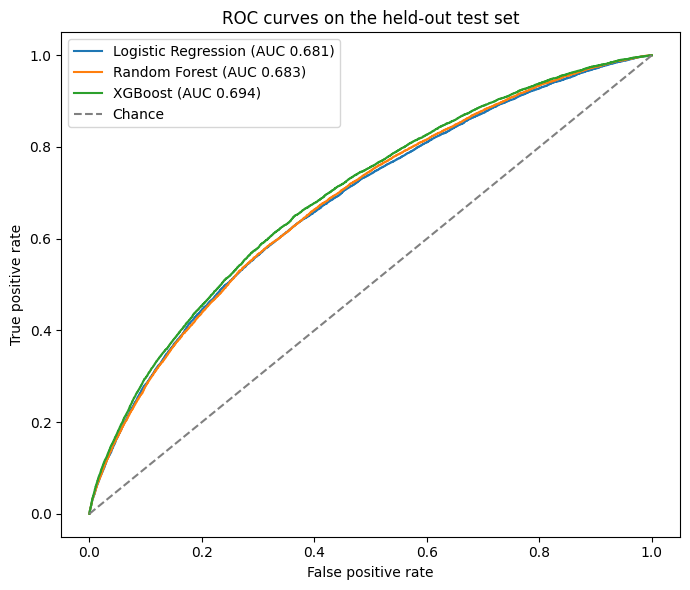

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve
from xgboost import XGBClassifier
from src.training import binary_metrics, positive_probability

negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_pos_weight = negative_count / positive_count
print(f"Training counts: paid={negative_count:,}, charged off={positive_count:,}; scale_pos_weight={scale_pos_weight:.3f}")

estimators = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", solver="lbfgs", max_iter=500, C=0.5, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=120, max_depth=14, min_samples_leaf=5,
        max_features="sqrt", class_weight="balanced_subsample",
        n_jobs=-1, random_state=42,
    ),
    "XGBoost": XGBClassifier(
        objective="binary:logistic", eval_metric="logloss",
        n_estimators=350, learning_rate=0.05, max_depth=4,
        min_child_weight=5, subsample=0.85, colsample_bytree=0.85,
        reg_lambda=2.0, scale_pos_weight=scale_pos_weight,
        tree_method="hist", n_jobs=4, random_state=42,
    ),
}
trained_models, validation_probabilities, test_probabilities = {}, {}, {}
comparison_rows = []
for model_name, estimator in estimators.items():
    print(f"Training {model_name} ...")
    pipeline = make_pipeline(estimator)
    pipeline.fit(X_train, y_train)
    validation_probability = positive_probability(pipeline, X_validation)
    test_probability = positive_probability(pipeline, X_test)
    validation_probabilities[model_name] = validation_probability
    test_probabilities[model_name] = test_probability
    trained_models[model_name] = pipeline
    validation_auc = binary_metrics(y_validation, validation_probability)["roc_auc"]
    test_result = binary_metrics(y_test, test_probability, threshold=0.5)
    comparison_rows.append({
        "Model": model_name, "Validation ROC-AUC": validation_auc,
        "Accuracy": test_result["accuracy"], "Precision (risky)": test_result["precision"],
        "Recall (risky)": test_result["recall"], "F1 (risky)": test_result["f1"],
        "Test ROC-AUC": test_result["roc_auc"],
    })
comparison = pd.DataFrame(comparison_rows).sort_values("Validation ROC-AUC", ascending=False)
display(comparison.style.format(precision=3))
best_model_name = comparison.iloc[0]["Model"]
best_pipeline = trained_models[best_model_name]
print("Selected on validation ROC-AUC:", best_model_name)

plt.figure(figsize=(7, 6))
for model_name, probabilities in test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = binary_metrics(y_test, probabilities)["roc_auc"]
    plt.plot(fpr, tpr, label=f"{model_name} (AUC {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves on the held-out test set")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Tune the risky-class threshold on validation only

Select the best model by validation ROC-AUC. Choose its probability cutoff by maximizing validation F1 for `Charged Off = 1`. Freeze a website borderline band of ±0.10: below it is STRONG, above it is RISKY, and inside it is BORDERLINE.

The test set is then evaluated once using the tuned cutoff. Confusion-matrix rows are actual outcomes and columns are predicted outcomes, ordered Fully Paid (0), Charged Off (1).

Validation-tuned cutoff: 0.5194
Validation risky-class F1 at cutoff: 0.4131


,value
threshold,0.519431
accuracy,0.676004
precision,0.320341
recall,0.581238
f1,0.413040
roc_auc,0.693647


Test triage counts: {'STRONG': 25133, 'BORDERLINE': 23379, 'RISKY': 10893}


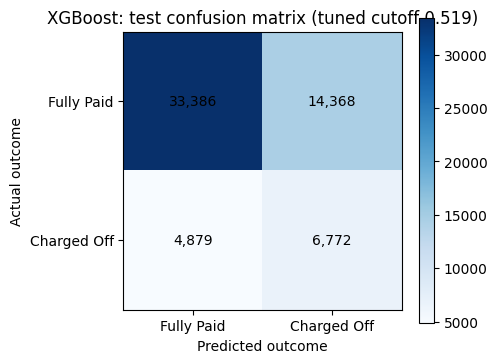

In [6]:
from src.training import choose_f1_threshold, triage_labels

best_validation_probability = validation_probabilities[best_model_name]
best_test_probability = test_probabilities[best_model_name]
threshold, validation_best_f1 = choose_f1_threshold(y_validation, best_validation_probability)
borderline_band = 0.10
best_test_tuned = binary_metrics(y_test, best_test_probability, threshold=threshold)
test_triage = triage_labels(best_test_probability, threshold, borderline_band)
print(f"Validation-tuned cutoff: {threshold:.4f}")
print(f"Validation risky-class F1 at cutoff: {validation_best_f1:.4f}")
display(pd.Series({k: v for k, v in best_test_tuned.items() if k != "confusion_matrix"}).to_frame("value"))
print("Test triage counts:", pd.Series(test_triage).value_counts().to_dict())

cm = np.asarray(best_test_tuned["confusion_matrix"])
fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1], ["Fully Paid", "Charged Off"])
ax.set_yticks([0, 1], ["Fully Paid", "Charged Off"])
ax.set_xlabel("Predicted outcome")
ax.set_ylabel("Actual outcome")
ax.set_title(f"{best_model_name}: test confusion matrix (tuned cutoff {threshold:.3f})")
for (row, column), value in np.ndenumerate(cm):
    ax.text(column, row, f"{value:,}", ha="center", va="center", color="black")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

## 7. Explain the best model with grouped SHAP values

TreeExplainer calculates contributions on transformed inputs. We sum one-hot SHAP columns back to their original feature, so the app says `purpose` rather than `purpose_car`. These explain model associations, not causes.

A reproducible sample of up to 1,000 test rows is used for global analysis. The bar chart shows mean absolute grouped SHAP values; the summary plot shows the grouped contribution distribution.

C:\Users\LENOVO\Desktop\INT 395\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,feature,mean_absolute_shap
0,term,0.306249
1,loan_to_income,0.225964
2,revol_util,0.207551
3,dti,0.194053
4,open_acc,0.125676
5,revol_bal_to_income,0.125386
6,home_ownership,0.119916
7,mort_acc,0.102552
8,total_acc,0.086660
9,purpose,0.080968


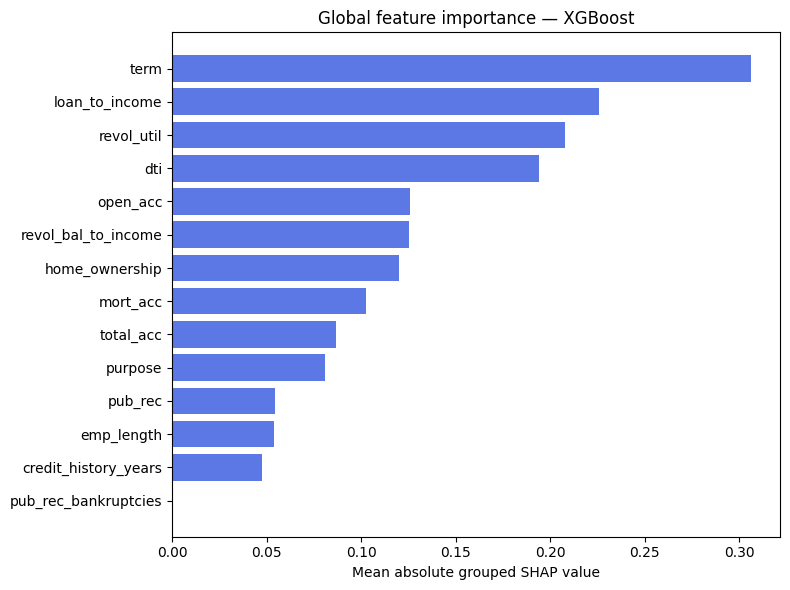

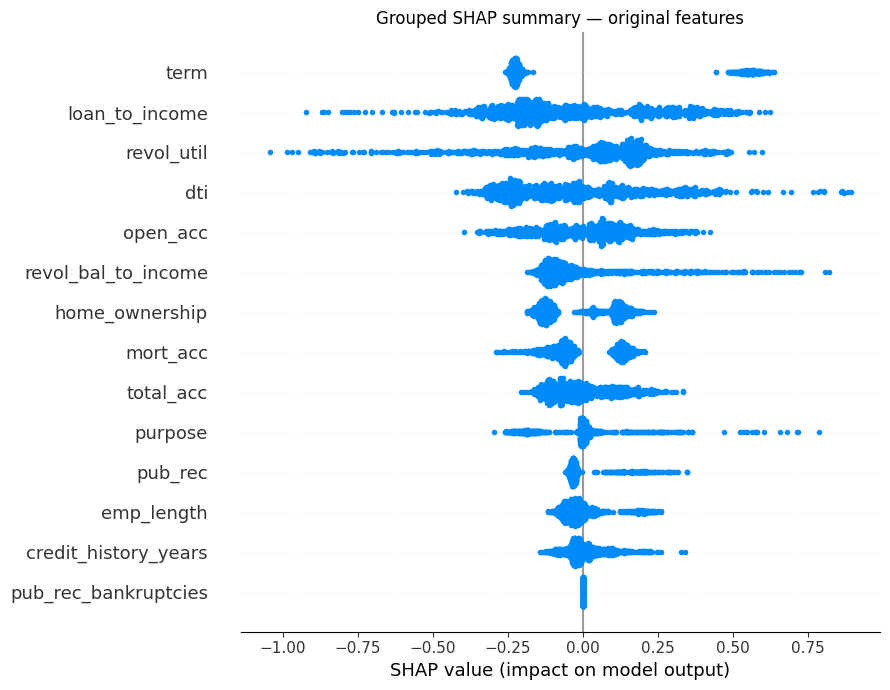

Top five global factors: ['term', 'loan_to_income', 'revol_util', 'dti', 'open_acc']


In [7]:
import shap
from src.features import FEATURES
from src.training import aggregate_shap, transformed_feature_groups

X_shap = X_test.sample(n=min(1000, len(X_test)), random_state=42)
preprocessor = best_pipeline.named_steps["preprocessor"]
X_shap_encoded = preprocessor.transform(X_shap)
if hasattr(X_shap_encoded, "toarray"):
    X_shap_encoded = X_shap_encoded.toarray()
shap_explainer = shap.TreeExplainer(best_pipeline.named_steps["model"])
shap_output = shap_explainer.shap_values(X_shap_encoded)
if hasattr(shap_output, "values"):
    shap_output = shap_output.values
encoded_names, original_feature_mapping = transformed_feature_groups(preprocessor)
grouped_shap_values = aggregate_shap(shap_output, original_feature_mapping)

mean_absolute_shap = np.abs(grouped_shap_values).mean(axis=0)
feature_importance = pd.DataFrame({
    "feature": FEATURES, "mean_absolute_shap": mean_absolute_shap,
}).sort_values("mean_absolute_shap", ascending=False).reset_index(drop=True)
display(feature_importance)

top_plot = feature_importance.sort_values("mean_absolute_shap")
plt.figure(figsize=(8, 6))
plt.barh(top_plot["feature"], top_plot["mean_absolute_shap"], color="#5b78e5")
plt.xlabel("Mean absolute grouped SHAP value")
plt.title(f"Global feature importance — {best_model_name}")
plt.tight_layout()
plt.show()

shap.summary_plot(
    grouped_shap_values, feature_names=FEATURES, max_display=len(FEATURES),
    show=False, plot_size=(9, 7),
)
plt.title("Grouped SHAP summary — original features")
plt.tight_layout()
plt.show()

feature_importance_records = [
    {"feature": str(row.feature), "mean_absolute_shap": float(row.mean_absolute_shap), "rank": int(index + 1)}
    for index, row in feature_importance.iterrows()
]
top_five_factors = [item["feature"] for item in feature_importance_records[:5]]
print("Top five global factors:", top_five_factors)

## 8. Create eight correctly predicted examples from the test set

Choose four test loans that are truly Fully Paid and confidently predicted STRONG, and four truly Charged Off loans confidently predicted RISKY. These are illustrative examples, not guarantees.

Source amounts are U.S. dollars. For display only, each money amount is multiplied by the brief's fixed factor of 20 to show rupees. This is not an exchange rate. Ratios stay approximately the same. Names, addresses, and row identifiers are omitted. Finally, we verify the rounded website inputs still get the intended label.

In [8]:
from src.features import build_features, map_purpose
from src.training import triage_labels
from src.training import pick_sample_rows

complete_test_rows = X_test.notna().all(axis=1).to_numpy()
sample_indices, _ = pick_sample_rows(
    y_test, best_test_probability, threshold, count=4, eligible_mask=complete_test_rows
)
display_year = pd.Timestamp.today().year
title_keys = {
    "strong": ["case_strong1", "case_strong2", "case_strong3", "case_strong4"],
    "risky": ["case_risky1", "case_risky2", "case_risky3", "case_risky4"],
}

def make_website_case(group, index, title_key):
    source_index = X_test.index[index]
    raw_row = raw.loc[source_index]
    feature_row = X_test.loc[source_index]
    annual_income = int(round(float(raw_row["annual_inc"]) * 20))
    existing_emi = int(round(float(feature_row["dti"]) / 100 * (float(raw_row["annual_inc"]) / 12) * 20))
    home_value = str(feature_row["home_ownership"])
    website_home = {"RENT": "rented", "OWN": "own", "MORTGAGE": "own_loan", "OTHER": "other"}[home_value]
    credit_year = int(display_year - float(feature_row["credit_history_years"]))
    if credit_year < 1950:
        raise ValueError("This example's first credit year is outside the website's supported range.")
    return {
        "id": f"{group}{title_key[-1]}", "group": group, "title_key": title_key,
        "values": {
            "age": 30, "employment": "Salaried", "job_years": int(round(float(feature_row["emp_length"]))),
            "home": website_home, "credit_year": credit_year,
            "annual_income": annual_income, "existing_emi": existing_emi,
            "card_bill": int(round(float(raw_row["revol_bal"]) * 20)),
            "revol_util": int(round(float(feature_row["revol_util"]))),
            "open_acc": int(round(float(feature_row["open_acc"]))),
            "total_acc": int(round(float(feature_row["total_acc"]))),
            "mort_acc": int(round(float(feature_row["mort_acc"]))),
            "pub_rec": int(round(float(feature_row["pub_rec"]))),
            "bankruptcies": int(round(float(feature_row["pub_rec_bankruptcies"]))),
            "cibil": "Don't know", "loan_amount": int(round(float(raw_row["loan_amnt"]) * 20)),
            "tenure_months": int(round(float(feature_row["term"]))),
            "purpose": map_purpose(raw_row["purpose"]), "rate": 11.0,
        },
    }

sample_cases, verified_groups = [], {"strong": [], "risky": []}
for group, indexes in sample_indices.items():
    for case_number, index in enumerate(indexes):
        candidate = make_website_case(group, index, title_keys[group][case_number])
        profile_features = pd.DataFrame([build_features(candidate["values"])], columns=FEATURES)
        profile_probability = positive_probability(best_pipeline, profile_features)[0]
        website_label = str(triage_labels([profile_probability], threshold, 0.10)[0])
        if website_label == group.upper():
            verified_groups[group].append(candidate)
    if len(verified_groups[group]) != 4:
        raise ValueError(f"Only {len(verified_groups[group])} rounded website examples verify as {group}.")
    sample_cases.extend(verified_groups[group])

display(pd.DataFrame([
    {"id": case["id"], "example group": case["group"],
     "loan / yearly income": case["values"]["loan_amount"] / case["values"]["annual_income"]}
    for case in sample_cases
]))
assert len(sample_cases) == 8
print("Verified 4 STRONG and 4 RISKY examples using the website feature builder.")

,id,example group,loan / yearly income
0,strong1,strong,0.041667
1,strong2,strong,0.023774
2,strong3,strong,0.022222
3,strong4,strong,0.027778
4,risky1,risky,0.379795
5,risky2,risky,0.353535
6,risky3,risky,0.400000
7,risky4,risky,0.359973


Verified 4 STRONG and 4 RISKY examples using the website feature builder.


## 9. Save artifacts and summarize the actual findings

Save the full preprocessing/model pipeline, validation threshold, comparison metrics, tuned test confusion matrix, ROC coordinates, grouped SHAP importance, and sample profiles. The raw CSV remains Git-ignored. The app reads these artifacts; its metrics are not manually typed.

The result remains a historical U.S. LendingClub model. It does not establish causation, measure current Indian credit outcomes, or guarantee approval.

In [9]:
from datetime import date
import joblib
from src.training import compact_roc

models_dir = Path("models")
models_dir.mkdir(exist_ok=True)
comparison_records = []
for name in estimators:
    row = comparison.loc[comparison["Model"] == name].iloc[0]
    default_test = binary_metrics(y_test, test_probabilities[name], threshold=0.5)
    comparison_records.append({
        "model": name,
        "validation_roc_auc": float(row["Validation ROC-AUC"]),
        "test_at_0_50": default_test,
    })
roc_curves = {
    name: {
        **compact_roc(y_test, test_probabilities[name]),
        "auc": float(binary_metrics(y_test, test_probabilities[name])["roc_auc"]),
    }
    for name in estimators
}
metadata = {
    "source_archive": "User-supplied archive (6).zip; embedded lending_club_loan_two.csv",
    "source_url": None,
    "retrieval_date": date.today().isoformat(),
    "license": "Unverified; no license or source metadata was included in the supplied archive. Verify before redistribution.",
    "geography": "United States LendingClub loans (platform context; verify against original documentation).",
    "observation_unit": "One loan record.",
    "issue_year_range": [
        int(pd.to_datetime(raw["issue_d"], format="%b-%Y").dt.year.min()),
        int(pd.to_datetime(raw["issue_d"], format="%b-%Y").dt.year.max()),
    ],
    "rows": int(len(raw)), "columns": int(raw.shape[1]), "csv_sha256": sha256,
    "duplicate_full_rows": int(raw.duplicated().sum()),
    "target_column": "loan_status", "target_mapping": target_map,
    "target_counts": {str(key): int(value) for key, value in raw["loan_status"].value_counts().items()},
    "missing_values": {str(key): int(value) for key, value in missing[missing.gt(0)].items()},
    "limitations": [
        "Source URL, license, and original data dictionary were absent from the supplied archive.",
        "Only Fully Paid and Charged Off loans are present; unresolved/current loans are not represented.",
        "Historical U.S. LendingClub outcomes are not validated for Indian borrowers or today's lending market.",
        "Random stratified splitting does not test temporal generalization across eras.",
    ],
}
metrics = {
    "dataset": metadata,
    "feature_names": FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "excluded_columns": LEAKAGE_AND_EXCLUDED,
    "model_selection": "Highest validation ROC-AUC; cutoff tuned on validation F1 for Charged Off.",
    "best_model": best_model_name,
    "best_test_tuned_threshold": best_test_tuned,
    "validation_tuned_threshold": float(threshold),
    "borderline_band": borderline_band,
    "validation_risky_f1_at_threshold": float(validation_best_f1),
    "comparison": comparison_records, "roc_curves": roc_curves,
    "confusion_matrix_labels": ["Fully Paid (0)", "Charged Off (1)"],
    "confusion_matrix": best_test_tuned["confusion_matrix"],
    "feature_importance": feature_importance_records,
    "threshold_notes": "STRONG below threshold - band; BORDERLINE within plus/minus band; RISKY above threshold + band.",
}
joblib.dump(best_pipeline, models_dir / "model.pkl", compress=3)
model_size = (models_dir / "model.pkl").stat().st_size
if model_size >= 50_000_000:
    raise ValueError(f"Model artifact is {model_size:,} bytes; required size is below 50 MB.")
(models_dir / "threshold.json").write_text(
    json.dumps({"threshold": float(threshold), "borderline_band": borderline_band}, indent=2), encoding="utf-8"
)
(models_dir / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
(models_dir / "feature_importance.json").write_text(json.dumps(feature_importance_records, indent=2), encoding="utf-8")
(Path("src") / "sample_cases.json").write_text(json.dumps(sample_cases, indent=2), encoding="utf-8")

print(f"Saved {best_model_name} pipeline: {model_size / 1_000_000:.2f} MB")
print("Wrote threshold, metrics, feature importance, and sample case artifacts.")
display(Markdown(f"""### Training summary
- **Selected model:** {best_model_name}
- **Test F1 for Charged Off:** {best_test_tuned['f1']:.3f}
- **Test recall / precision:** {best_test_tuned['recall']:.3f} / {best_test_tuned['precision']:.3f}
- **Test ROC-AUC:** {best_test_tuned['roc_auc']:.3f}
- **Validation-selected cutoff:** {threshold:.3f} with plus/minus {borderline_band:.2f} band
- **Top five grouped SHAP factors:** {', '.join(top_five_factors)}

**Limitations:** source license and data dictionary remain unverified; data are old U.S. outcomes and do not validate an Indian readiness tool. Feature associations are not causes, and the model cannot guarantee approval."""))


Saved XGBoost pipeline: 0.15 MB
Wrote threshold, metrics, feature importance, and sample case artifacts.


### Training summary
- **Selected model:** XGBoost
- **Test F1 for Charged Off:** 0.413
- **Test recall / precision:** 0.581 / 0.320
- **Test ROC-AUC:** 0.694
- **Validation-selected cutoff:** 0.519 with plus/minus 0.10 band
- **Top five grouped SHAP factors:** term, loan_to_income, revol_util, dti, open_acc

**Limitations:** source license and data dictionary remain unverified; data are old U.S. outcomes and do not validate an Indian readiness tool. Feature associations are not causes, and the model cannot guarantee approval.